In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import logging
from pathlib import Path
import os

from ema_workbench.analysis import prim
from ema_workbench import ema_logging
ema_logging.log_to_stderr(logging.WARNING)

%matplotlib inline

In [20]:
# ── Pick a results file ────────────────────────────────────────────────────────
RESULTS_ROOT = Path("data/multi_run/output")

# Auto: most recent scenario_400 run. Override by hardcoding:
# RESULTS_PATH = Path("data/multi_run/output/20260407_121305_scenario_400/results.csv")
candidates = sorted(RESULTS_ROOT.glob("*scenario_400*/results.csv"), key=os.path.getmtime)
RESULTS_PATH = candidates[-1]

df = pd.read_csv(RESULTS_PATH)
print(f"Loaded: {RESULTS_PATH}  ({len(df)} rows)")

UNCERTAINTY_COLS = ['bcas_rate', 'wave_duration_min', 'waves_per_day', 'n_battalions_in_combat']
x = df[UNCERTAINTY_COLS].astype(float)  # cast to float to avoid ema_workbench int64 paste error

Loaded: data\multi_run\output\20260407_141646_scenario_400\results.csv  (1000 rows)


## T1 — high mortality

In [21]:
threshold_T1 = df['death_rate_T1_BCAS'].quantile(0.75)
y_T1 = (df['death_rate_T1_BCAS'] >= threshold_T1).values
print(f"T1 threshold: {threshold_T1:.3f}  |  cases of interest: {y_T1.sum()}/{len(y_T1)}")

prim_T1 = prim.Prim(x, y_T1, threshold=0.4, peel_alpha=0.05, mass_min=0.02)
box_T1 = prim_T1.find_box()

T1 threshold: 0.643  |  cases of interest: 252/1000


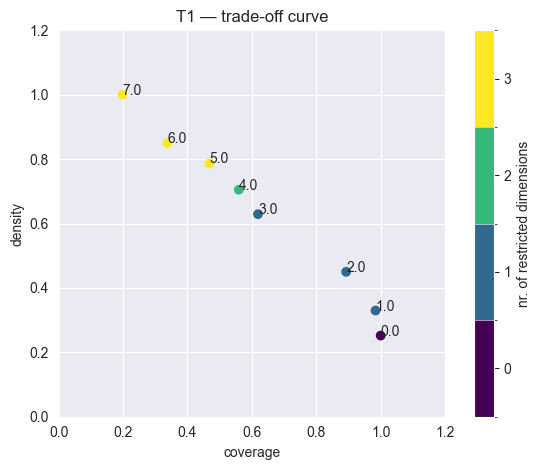

In [22]:
box_T1.show_tradeoff(annotated=True)
plt.title('T1 — trade-off curve')
plt.tight_layout()
plt.show()

Point 2  |  coverage=0.893  density=0.450


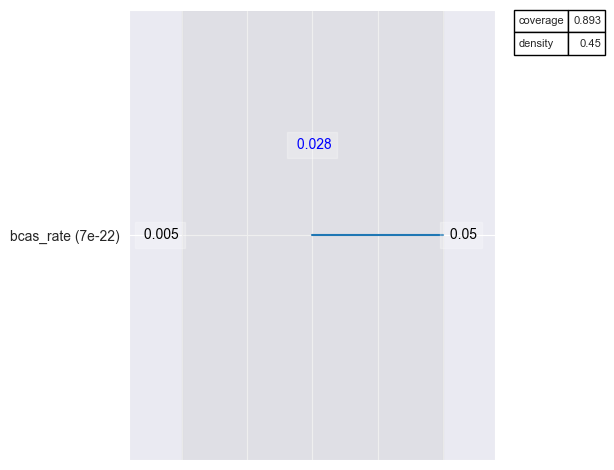

In [23]:
# Change this to whatever point looks best on the trade-off curve above
POINT_T1 = None  # None = auto-select

traj = box_T1.peeling_trajectory
if POINT_T1 is None:
    pt = traj[traj['density'] >= 0.4].sort_values('coverage', ascending=False)
    POINT_T1 = int(pt.index[0]) if len(pt) else int(len(traj) // 2)
else:
    POINT_T1 = int(POINT_T1)

row = traj.loc[POINT_T1]
print(f"Point {POINT_T1}  |  coverage={row['coverage']:.3f}  density={row['density']:.3f}")
box_T1.inspect(POINT_T1, style='graph')
plt.tight_layout()
plt.show()

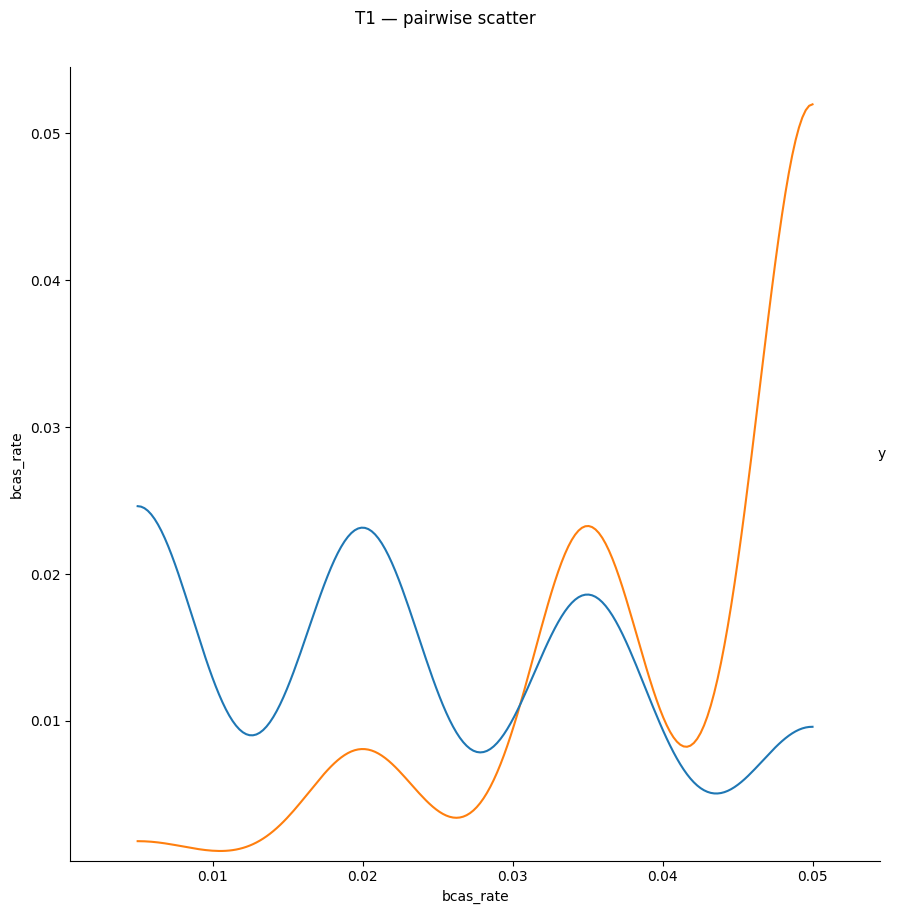

In [6]:
box_T1.select(POINT_T1)
box_T1.show_pairs_scatter()
plt.gcf().set_size_inches(9, 9)
plt.suptitle('T1 — pairwise scatter', y=1.01)
plt.tight_layout()
plt.show()

y_T2 = (df['death_rate_T2_BCAS'] > 0).values
print(f"T2 cases of interest (any T2 death): {y_T2.sum()}/{len(y_T2)}")

prim_T2 = prim.Prim(x, y_T2, threshold=0.4, peel_alpha=0.05, mass_min=0.02)
box_T2 = prim_T2.find_box()

In [7]:
y_T2 = (df['death_rate_T2_BCAS'] > 0).values
print(f"T2 cases of interest (any T2 death): {y_T2.sum()}/{len(y_T2)}")

prim_T2 = prim.Prim(x, y_T2, threshold=0.4, peel_alpha=0.05, mass_min=0.02)
box_T2 = prim_T2.find_box()

T2 cases of interest (any T2 death): 136/1000


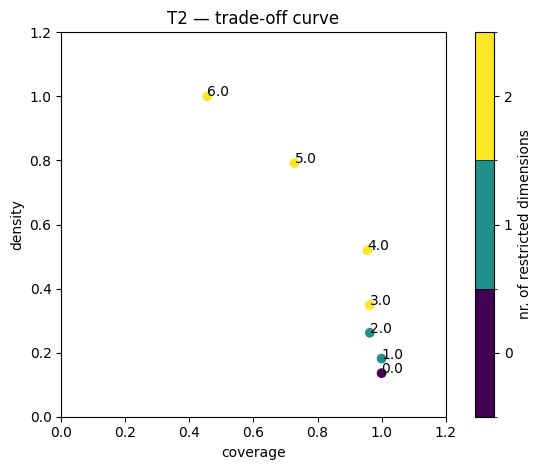

In [8]:
box_T2.show_tradeoff(annotated=True)
plt.title('T2 — trade-off curve')
plt.tight_layout()
plt.show()

Point 4  |  coverage=0.956  density=0.520


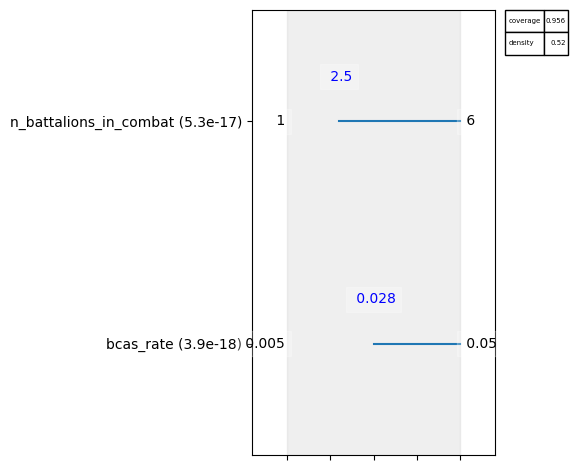

In [9]:
# Change this to whatever point looks best on the trade-off curve above
POINT_T2 = None  # None = auto-select

traj = box_T2.peeling_trajectory
if POINT_T2 is None:
    pt = traj[traj['density'] >= 0.4].sort_values('coverage', ascending=False)
    POINT_T2 = int(pt.index[0]) if len(pt) else int(len(traj) // 2)
else:
    POINT_T2 = int(POINT_T2)

row = traj.loc[POINT_T2]
print(f"Point {POINT_T2}  |  coverage={row['coverage']:.3f}  density={row['density']:.3f}")
box_T2.inspect(POINT_T2, style='graph')
plt.tight_layout()
plt.show()

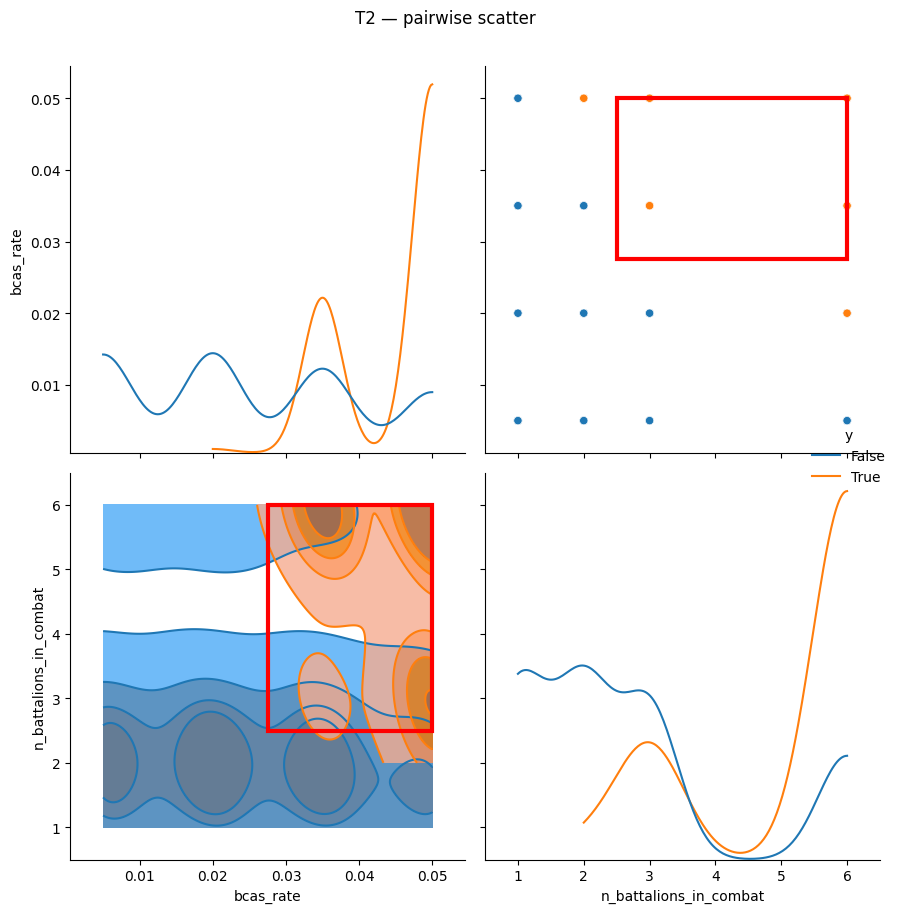

In [10]:
box_T2.select(POINT_T2)
box_T2.show_pairs_scatter()
plt.gcf().set_size_inches(9, 9)
plt.suptitle('T2 — pairwise scatter', y=1.01)
plt.tight_layout()
plt.show()